# IDORT literature tests: beams, shadow, emitting cylinder, radiative shocks

The literature tests of the IDORT paper (Ma et al. 2025) and Jiang (2021, ApJS 253, 49) with
the production keys (`decks/idort_*.athinput`), each against an exact or semi-analytic solution:

- **crossing beams** in vacuum (`idort_beams`): two beams enter at $x_1 = -2$ at $\pm 45$ deg;
  exact: the straight beams. Also on 4 MeshBlocks (`idort_beams_mb`, no plot: identical in
  tile mode along $x_2$, $3\times10^{-12}$ in block mode along $x_1$).
- **shadow** (`idort_shadow`, ring of 12 rays; `idort_shadow_gl`, the general $8\times32$ set):
  two beams at $\pm15$ deg past an opaque ellipse; exact: the beams attenuated along straight rays.
- **emitting cylinder** (`idort_cylinder`): $r<1$, $\rho\kappa = 10$, $aT^4 = 1$ in vacuum;
  exact: the transport solution along $y = 0$ (`ref/idort_cylinder_exact.npz`).
- **radiative shocks** (`idort_radshock_m2`, `idort_radshock_m5`): Lowrie & Edwards (2008) at
  Mach 2 and 5, started from the semi-analytic profile (`ref/idort_radshock_m*.txt`), which the
  scheme must keep.
- **hot gas cooling into radiation** at large steps (`idort_thermal_eq2`): $T(t)$ against the exact ODE.

Criteria: L1 within 5 % of the reference values (see `ref/references.json`). Code units
except the shocks (cgs).

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath('.'))   # this notebook's folder: tests/vet_clean/notebooks
import nbutil as nb                        # nb.suite, nb.verdict, nb.vett (readers), nb.rt (run_tests)

# the athena binary (a CPU build, default the one tests/vet_clean/run_tests.sh builds)
EXE = os.path.abspath(os.environ.get('ATHENA_EXE', '../../../build_vettest/src/athena'))
# where the runs go; a test whose run is already there is only loaded, not rerun
WORK = os.path.abspath(os.environ.get('VET_NB_WORKDIR', 'runs'))
THREADS = int(os.environ.get('VET_NB_THREADS', '4'))   # OpenMP threads per run
plt.rcParams.update({'figure.dpi': 80, 'savefig.dpi': 80, 'font.size': 10})
print('binary', os.path.relpath(EXE), '\nruns  ', os.path.relpath(WORK))

binary ../../../build_vettest/src/athena 
runs   runs


In [2]:
TESTS = ['idort_beams', 'idort_beams_mb', 'idort_shadow', 'idort_shadow_gl', 'idort_cylinder',
         'idort_radshock_m2', 'idort_radshock_m5', 'idort_thermal_eq2']
res = {t: nb.suite(t, EXE, WORK, THREADS) for t in TESTS}
vett, rt = nb.vett, nb.rt

loading the existing run runs/idort_beams
loading the existing run runs/idort_beams_mb
loading the existing run runs/idort_shadow
loading the existing run runs/idort_shadow_gl
loading the existing run runs/idort_cylinder
loading the existing run runs/idort_radshock_m2
loading the existing run runs/idort_radshock_m5
loading the existing run runs/idort_thermal_eq2


## Crossing beams

Left: E of the run; middle: the exact straight beams (cell averages); right: cuts across the
beams at four heights $x_1$ (lines: code, dashed: exact). The beams, 4 cells wide, stay straight
and go on after crossing; they carry 1.20 times the exact energy (`lum_top`), which
dominates L1; the energy flux through every row equals the injected flux to 6e-8 (`flux_err`).

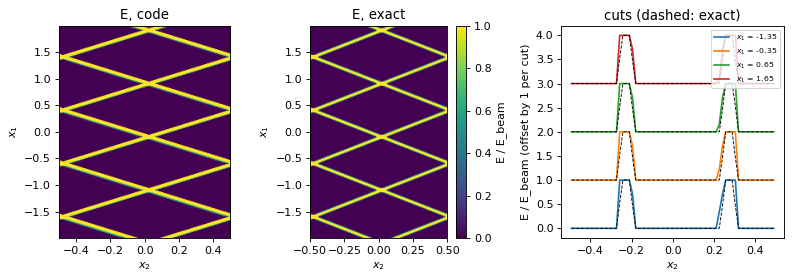

PASS idort_beams   criterion {"max": {"flux_err": 1e-05}, "near": {"L1": [0.2015, 0.05], "lum_top": [1.2036, 0.05]}}
PASS idort_beams_mb   criterion {"equal": {"maxdiff_tile_x2": 0.0}, "max": {"maxdiff_block_x1": 1e-08}}


In [3]:
d = os.path.join(WORK, 'idort_beams', 'run')
E, Ex = vett.last_bin(d, 'vet')['vet_e'][0], rt.beams_exact(d)
x1, x2, _ = vett.cell_centres(d)
fig, axs = plt.subplots(1, 3, figsize=(10, 3.6), gridspec_kw={'width_ratios': [1, 1, 1.3]})
ext = [x2[0] - 0.5*(x2[1] - x2[0]), x2[-1] + 0.5*(x2[1] - x2[0]), x1[0], x1[-1]]
for a, f, t in ((axs[0], E, 'code'), (axs[1], Ex, 'exact')):
    im = a.imshow(f.T, origin='lower', extent=ext, aspect='auto', vmin=0, vmax=1, cmap='viridis')
    a.set(xlabel='$x_2$', ylabel='$x_1$', title='E, ' + t)
fig.colorbar(im, ax=axs[1], label='E / E_beam')
for k, r in enumerate((-1.35, -0.35, 0.65, 1.65)):
    i = int(np.argmin(np.abs(x1 - r)))
    axs[2].plot(x2, E[:, i] + k, '-', c='C%d' % k, label='$x_1$ = %.2f' % x1[i])
    axs[2].plot(x2, Ex[:, i] + k, 'k--', lw=0.8)
axs[2].set(xlabel='$x_2$', ylabel='E / E_beam (offset by 1 per cut)', title='cuts (dashed: exact)')
axs[2].legend(fontsize=7, loc='upper right')
plt.tight_layout(); plt.show()
for t in ('idort_beams', 'idort_beams_mb'):
    nb.verdict(t, res[t])

## Shadow

Left: E of the ring run, log scale. Right: cuts along $x_2$ behind the ellipse (at
$x_1 = 0.25$ and $0.4$) for both ray sets with the exact attenuated beams (the general set
snaps the beams to its nearest rays, 11.4 deg; its exact field uses that angle).

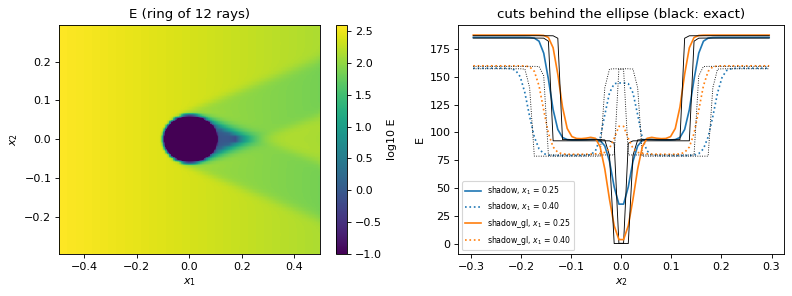

PASS idort_shadow   criterion {"near": {"L1": [0.0138, 0.05]}}
PASS idort_shadow_gl   criterion {"near": {"L1": [0.0126, 0.05]}}


In [4]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
for t, c in (('idort_shadow', 'C0'), ('idort_shadow_gl', 'C1')):
    d = os.path.join(WORK, t, 'run')
    E, Ex = vett.last_bin(d, 'vet')['vet_e'][0], rt.shadow_exact(d)
    x1, x2, _ = vett.cell_centres(d)
    if t == 'idort_shadow':
        im = axs[0].imshow(np.log10(np.maximum(E, 1e-3)), origin='lower', aspect='auto',
                           extent=[x1[0], x1[-1], x2[0], x2[-1]], vmin=-1, vmax=np.log10(400))
        fig.colorbar(im, ax=axs[0], label='log10 E')
        axs[0].set(xlabel='$x_1$', ylabel='$x_2$', title='E (ring of 12 rays)')
    for xc, ls in ((0.25, '-'), (0.4, ':')):
        i = int(np.argmin(np.abs(x1 - xc)))
        axs[1].plot(x2, E[:, i], ls, c=c, label='%s, $x_1$ = %.2f' % (t[6:], x1[i]))
        axs[1].plot(x2, Ex[:, i], ls, c='k', lw=0.8)
axs[1].set(xlabel='$x_2$', ylabel='E', title='cuts behind the ellipse (black: exact)')
axs[1].legend(fontsize=7)
plt.tight_layout(); plt.show()
for t in ('idort_shadow', 'idort_shadow_gl'):
    nb.verdict(t, res[t])

## Emitting cylinder

E, the energy flux $\Phi_x/c$ (`vet_phi1`) and the face momentum $F_x/c$ (`vet_f1`) along
$y = 0$ against the exact transport solution. Outside the cylinder E agrees to 1.1 % and the
energy flux to 1.2 % (`F_out`); the face momentum is about 20 % above the exact flux
(`FH_out`, a regression reference).

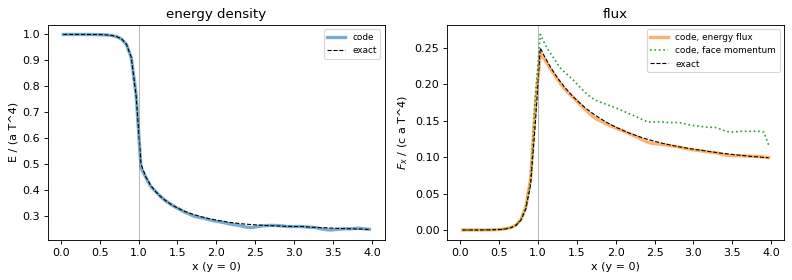

PASS idort_cylinder   criterion {"near": {"E_in": [0.000531, 0.05], "E_out": [0.0111, 0.05], "F_out": [0.0116, 0.05], "FH_out": [0.203, 0.05]}}


True

In [5]:
d = os.path.join(WORK, 'idort_cylinder', 'run')
m, (x1, x2, _) = vett.last_bin(d, 'vet'), vett.cell_centres(d)
ex = np.load(os.path.join(nb.SUITE, 'ref', 'idort_cylinder_exact.npz'))
j, s = np.argsort(np.abs(x2))[:2], x1 > 0
cl = float(vett.parse_deck_text(open(os.path.join(d, 'in.athinput')).read())['rad_vet']['c_light'])
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
axs[0].plot(x1[s], m['vet_e'][0][j].mean(axis=0)[s], 'C0-', lw=3, alpha=0.6, label='code')
axs[0].plot(ex['x'], ex['E'], 'k--', lw=1, label='exact')
axs[1].plot(x1[s], m['vet_phi1'][0][j].mean(axis=0)[s]/cl, 'C1-', lw=3, alpha=0.6,
            label='code, energy flux')
axs[1].plot(x1[s], m['vet_f1'][0][j].mean(axis=0)[s]/cl, 'C2:', lw=1.5, label='code, face momentum')
axs[1].plot(ex['x'], ex['F'], 'k--', lw=1, label='exact')
for a, y in zip(axs, ('E / (a T^4)', '$F_x$ / (c a T^4)')):
    a.axvline(1.0, c='grey', lw=0.5); a.set(xlabel='x (y = 0)', ylabel=y); a.legend(fontsize=8)
axs[0].set_title('energy density'); axs[1].set_title('flux')
plt.tight_layout(); plt.show()
nb.verdict('idort_cylinder', res['idort_cylinder'])

## Radiative shocks (Lowrie & Edwards 2008)

Density (top) and gas and radiation temperatures (bottom) at $t = 2\times10^{-10}$ s against
the semi-analytic profiles, Mach 2 (left) and Mach 5 (right), 256 cells; $x_s$ is the shock
position of the reference. No shift is applied.

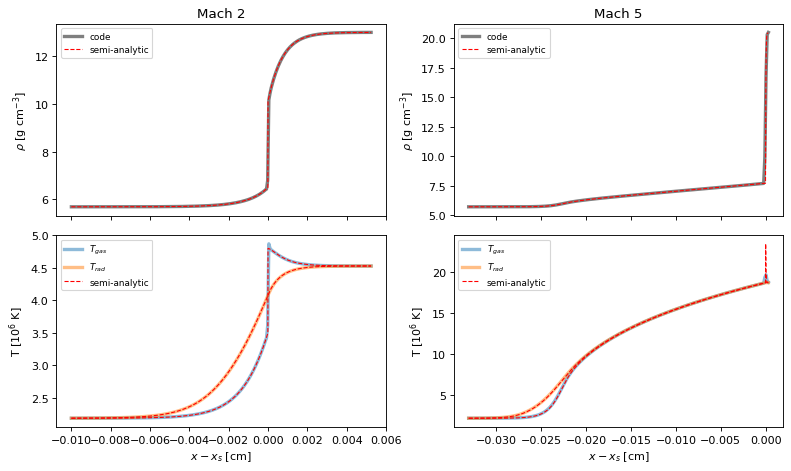

PASS idort_radshock_m2   criterion {"near": {"L1_rho": [0.000383, 0.05], "L1_v": [0.000245, 0.05], "L1_Tg": [0.000396, 0.05], "L1_Tr": [0.000271, 0.05]}}
PASS idort_radshock_m5   criterion {"near": {"L1_rho": [0.00216, 0.05], "L1_v": [0.000919, 0.05], "L1_Tg": [0.00181, 0.05], "L1_Tr": [0.00103, 0.05]}}


In [6]:
fig, axs = plt.subplots(2, 2, figsize=(10, 6), sharex='col')
for col, m in enumerate(('2', '5')):
    t = 'idort_radshock_m' + m
    d = os.path.join(WORK, t, 'run')
    p = vett.parse_deck_text(open(os.path.join(d, 'in.athinput')).read())
    tu, ar = float(p['problem']['vet_shock_tunit']), float(p['rad_vet']['arad'])
    h, r = vett.last_bin(d, 'hydro_w'), vett.last_bin(d, 'vet')
    x = vett.cell_centres(d)[0] - float(p['problem']['vet_shock_xs'])
    rho = h['dens'].mean(axis=(0, 1))
    tg = (2.0/3.0)*h['eint'].mean(axis=(0, 1))/rho/tu
    tr = (np.maximum(r['vet_e'].mean(axis=(0, 1)), 0.0)/ar)**0.25/tu
    a = np.loadtxt(os.path.join(nb.SUITE, 'ref', t + '.txt'))
    a = a[(a[:, 0] >= x[0]) & (a[:, 0] <= x[-1])]
    axs[0, col].plot(x, rho, 'k-', lw=3, alpha=0.5, label='code')
    axs[0, col].plot(a[:, 0], a[:, 1], 'r--', lw=1, label='semi-analytic')
    axs[1, col].plot(x, tg/1e6, 'C0-', lw=3, alpha=0.5, label='$T_{gas}$')
    axs[1, col].plot(x, tr/1e6, 'C1-', lw=3, alpha=0.5, label='$T_{rad}$')
    axs[1, col].plot(a[:, 0], a[:, 3]/1e6, 'r--', lw=1, label='semi-analytic')
    axs[1, col].plot(a[:, 0], a[:, 4]/1e6, 'r--', lw=1)
    axs[0, col].set(title='Mach ' + m, ylabel=r'$\rho$ [g cm$^{-3}$]')
    axs[1, col].set(xlabel='$x - x_s$ [cm]', ylabel='T [$10^6$ K]')
    axs[0, col].legend(fontsize=8); axs[1, col].legend(fontsize=8)
plt.tight_layout(); plt.show()
for t in ('idort_radshock_m2', 'idort_radshock_m5'):
    nb.verdict(t, res[t])

## Hot gas cooling into radiation at large time steps

Uniform gas ($T_0 = 100$) and radiation ($E_0 = 1$), $\kappa = 1$, $c = 100$, $\Delta t =
5\times10^{-4}$: each step is 5 to $10^5$ relaxation times. Left: $T(t)$ with the exact
equilibrium; right: $|T/T_{exact} - 1|$ (the first dump, after 5 steps, dominates).

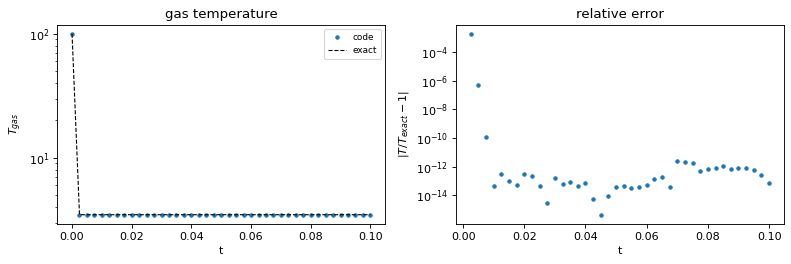

PASS idort_thermal_eq2   criterion {"near": {"errT": [0.00196, 0.05]}, "max": {"dEtot": 1e-13}}


True

In [7]:
d = os.path.join(WORK, 'idort_thermal_eq2', 'run')
p = vett.parse_deck_text(open(os.path.join(d, 'in.athinput')).read())
rho, gm1 = float(p['problem']['gas_rho']), float(p['hydro']['gamma']) - 1.0
T0, E0 = float(p['problem']['gas_eint'])*gm1/rho, float(p['problem']['e_rad'])
rate = float(p['rad_vet']['c_light'])*float(p['rad_vet']['kappa_p'])*rho
ts, T, Tx = [], [], []
for f in vett.bins(d, 'hydro_w'):
    h = vett.read_bin(f)
    ts.append(h['time']); T.append((h['eint']*gm1/h['dens']).mean())
    Tx.append(vett.relax_ode(T0, rho*T0/gm1 + E0, rho, gm1, rate, h['time']) if h['time'] > 0 else T0)
ts, T, Tx = np.array(ts), np.array(T), np.array(Tx)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
axs[0].semilogy(ts, T, 'o', ms=3, label='code'); axs[0].semilogy(ts, Tx, 'k--', lw=1, label='exact')
axs[0].set(xlabel='t', ylabel='$T_{gas}$', title='gas temperature'); axs[0].legend(fontsize=8)
axs[1].semilogy(ts[1:], np.maximum(np.abs(T[1:]/Tx[1:] - 1.0), 1e-17), 'o', ms=3)
axs[1].set(xlabel='t', ylabel='$|T/T_{exact} - 1|$', title='relative error')
plt.tight_layout(); plt.show()
nb.verdict('idort_thermal_eq2', res['idort_thermal_eq2'])